In [42]:
import os
import pandas as pd
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Cari file .env mulai dari folder kerja notebook, naik ke folder induk
env_path = find_dotenv(usecwd=True)
if not env_path:
    raise FileNotFoundError(
        "File .env tidak ditemukan. Buat .env di folder proyek (sql-ecommerce-analysis)."
    )
load_dotenv(env_path)

# Pastikan semua variabel terisi
required = ["DB_HOST", "DB_PORT", "DB_NAME", "DB_USER", "DB_PASSWORD"]
missing = [name for name in required if not os.getenv(name)]
if missing:
    raise EnvironmentError(f"Variabel belum terisi di .env: {missing}")

print("Konfigurasi .env berhasil dibaca.")

Konfigurasi .env berhasil dibaca.


In [43]:
db_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(db_url)

# Tes koneksi: engine baru benar-benar terhubung saat query pertama dijalankan
with engine.connect() as conn:
    info = conn.execute(text("SELECT current_database(), current_user")).fetchone()
print(f"Terhubung ke database '{info[0]}' sebagai user '{info[1]}'")

Terhubung ke database 'itversity_retail_db' sebagai user 'itversity_retail_user'


In [44]:
orders = pd.read_sql("SELECT * FROM orders", engine)
order_items = pd.read_sql("SELECT * FROM order_items", engine)
products = pd.read_sql("SELECT * FROM products", engine)
categories = pd.read_sql("SELECT * FROM categories", engine)
departments = pd.read_sql("SELECT * FROM departments", engine)
customers = pd.read_sql("SELECT * FROM customers", engine)

In [45]:
tables = {
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "categories": categories,
    "departments": departments,
    "customers": customers,
}

for name, df in tables.items():
    print(f"{name:<12} {df.shape[0]:>9,} baris x {df.shape[1]} kolom")

orders          68,883 baris x 4 kolom
order_items    172,198 baris x 6 kolom
products         1,345 baris x 6 kolom
categories          58 baris x 3 kolom
departments          6 baris x 2 kolom
customers       12,435 baris x 9 kolom


In [46]:
orders.head()

,order_id,order_date,order_customer_id,order_status
0,1,2013-07-25,11599,CLOSED
1,2,2013-07-25,256,PENDING_PAYMENT
2,3,2013-07-25,12111,COMPLETE
3,4,2013-07-25,8827,CLOSED
4,5,2013-07-25,11318,COMPLETE


In [47]:
orders.dtypes

order_id                      int64
order_date           datetime64[us]
order_customer_id             int64
order_status                    str
dtype: object

In [48]:
orders.isna().sum()

order_id             0
order_date           0
order_customer_id    0
order_status         0
dtype: int64

In [49]:
valid_orders = orders[orders["order_status"].isin(["COMPLETE", "CLOSED"])]

valid_items = valid_orders.merge(
    order_items,
    left_on="order_id",
    right_on="order_item_order_id",
    how="inner",
)

print("Order valid                    :", len(valid_orders))                        # target 30455
print("Order valid yang punya item    :", valid_items["order_id"].nunique())      # target 25266
print("Total valid revenue (USD)      :", round(valid_items["order_item_subtotal"].sum(), 2))  # target 15012982.48

Order valid                    : 30455
Order valid yang punya item    : 25266
Total valid revenue (USD)      : 15012982.48


## Kasus 1: Audit Orphan Orders (Pesanan Tanpa Item)

**Pertanyaan:** Apakah order yang tidak punya item di `order_items` terkonsentrasi di status atau periode tertentu, atau tersebar merata?

**Metode:** `left merge` antara `orders` dan `order_items`; baris dengan `order_item_id` kosong dianggap orphan. Status yang besar otomatis punya orphan lebih banyak, sehingga perbandingan memakai **orphan rate** (persentase orphan di dalam tiap status dan tiap bulan), bukan jumlah mentah. Jika orphan tidak terkait status, rate tiap status seharusnya mendekati tingkat keseluruhan. Hasil divalidasi dengan angka SQL (5.189 orphan pada `COMPLETE` + `CLOSED`) dan dengan jalur kedua memakai `isin()`.

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
orders_audit = pd.merge(
    orders,
    order_items,
    left_on="order_id",
    right_on="order_item_order_id",
    how="left",
)

orphan_orders = orders_audit[orders_audit["order_item_id"].isna()]

n_orphans = orphan_orders["order_id"].nunique()
print("Jumlah orphan orders (semua status):", n_orphans)
print("Baris orders_audit:", len(orders_audit), "| 172198 + orphan =", 172198 + n_orphans)

print("\nDistribusi status pada orphan orders:")
print(orphan_orders["order_status"].value_counts())

Jumlah orphan orders (semua status): 11452
Baris orders_audit: 183650 | 172198 + orphan = 183650

Distribusi status pada orphan orders:
order_status
COMPLETE           3934
PENDING_PAYMENT    2449
PROCESSING         1375
CLOSED             1255
PENDING            1225
ON_HOLD             605
SUSPECTED_FRAUD     254
CANCELED            234
PAYMENT_REVIEW      121
Name: count, dtype: int64


In [52]:
orphan_by_status = pd.DataFrame({
    "total_orders": orders["order_status"].value_counts(),
    "orphan_orders": orphan_orders["order_status"].value_counts(),
}).fillna(0).astype(int)

overall_rate = orphan_by_status["orphan_orders"].sum() / orphan_by_status["total_orders"].sum() * 100

orphan_by_status["orphan_rate_pct"] = (
    orphan_by_status["orphan_orders"] / orphan_by_status["total_orders"] * 100
).round(2)
orphan_by_status["share_of_orphans_pct"] = (
    orphan_by_status["orphan_orders"] / orphan_by_status["orphan_orders"].sum() * 100
).round(2)
orphan_by_status["share_of_all_orders_pct"] = (
    orphan_by_status["total_orders"] / orphan_by_status["total_orders"].sum() * 100
).round(2)

print(f"Tingkat orphan keseluruhan: {overall_rate:.2f}%")
orphan_by_status.sort_values("total_orders", ascending=False)

Tingkat orphan keseluruhan: 16.63%


,total_orders,orphan_orders,orphan_rate_pct,share_of_orphans_pct,share_of_all_orders_pct
order_status,,,,,
COMPLETE,22899,3934,17.18,34.35,33.24
PENDING_PAYMENT,15030,2449,16.29,21.38,21.82
PROCESSING,8275,1375,16.62,12.01,12.01
PENDING,7610,1225,16.10,10.70,11.05
CLOSED,7556,1255,16.61,10.96,10.97
ON_HOLD,3798,605,15.93,5.28,5.51
SUSPECTED_FRAUD,1558,254,16.30,2.22,2.26
CANCELED,1428,234,16.39,2.04,2.07
PAYMENT_REVIEW,729,121,16.60,1.06,1.06


In [53]:
orders_check = orders[["order_id", "order_date", "order_status"]].copy()
orders_check["is_orphan"] = ~orders_check["order_id"].isin(order_items["order_item_order_id"])
orders_check["order_month"] = orders_check["order_date"].dt.strftime("%Y-%m")

# Jalur kedua: hasilnya harus sama dengan hasil merge
print("Orphan lewat isin():", orders_check["is_orphan"].sum(), "| lewat merge:", n_orphans)

# Arah sebaliknya: item yang order induknya tidak ada (diharapkan 0)
print("Item tanpa order induk:", (~order_items["order_item_order_id"].isin(orders["order_id"])).sum())

# Apakah orphan terkonsentrasi di periode tertentu?
orphan_by_month = orders_check.groupby("order_month")["is_orphan"].agg(
    total_orders="size",
    orphan_orders="sum",
    orphan_rate_pct=lambda s: round(s.mean() * 100, 2),
)
orphan_by_month

Orphan lewat isin(): 11452 | lewat merge: 11452
Item tanpa order induk: 0


,total_orders,orphan_orders,orphan_rate_pct
order_month,,,
2013-07,1533,244,15.92
2013-08,5680,941,16.57
2013-09,5841,971,16.62
2013-10,5335,897,16.81
2013-11,6381,1071,16.78
2013-12,5892,969,16.45
2014-01,5908,984,16.66
2014-02,5635,960,17.04
2014-03,5778,993,17.19


In [54]:
from scipy.stats import chi2_contingency

kontingensi = pd.crosstab(orders_check["order_status"], orders_check["is_orphan"])
chi2, p_value, dof, expected = chi2_contingency(kontingensi)
print(f"p-value: {p_value:.4f}")

p-value: 0.3173


### Temuan

- **11.452 dari 68.883 order (16,63%) tidak punya item.** Sebanyak 57.431 order punya minimal satu item.
- **Orphan tersebar merata di semua status.** Orphan rate tiap status berkisar 15,93% (`ON_HOLD`) sampai 17,18% (`COMPLETE`), dekat dengan tingkat keseluruhan 16,63%. Porsi tiap status di antara orphan juga hampir sama dengan porsinya di antara seluruh order (misalnya `COMPLETE` 34,35% vs 33,24%, `PENDING_PAYMENT` 21,38% vs 21,82%).
- **Orphan tersebar merata di semua bulan.** Rate bulanan berkisar 15,58% (2014-07) sampai 17,19% (2014-03), tanpa lonjakan di periode tertentu.
- **Validasi:** orphan pada `COMPLETE` (3.934) + `CLOSED` (1.255) = **5.189**, sama dengan temuan SQL pada hari 2.

### Interpretasi

Selisih antar status (maksimum ±1,25 poin persentase) dan antar bulan masih berada di kisaran fluktuasi acak untuk ukuran kelompoknya. `COMPLETE` sedikit lebih tinggi (17,18%), tetapi satu angka yang menyimpang tipis dari sembilan status belum cukup untuk menyimpulkan adanya keterkaitan.

Jadi ketiadaan item **tidak terkait dengan status order maupun waktu**. Bukan hanya order batal atau pending yang kosong: order `COMPLETE` dan `CLOSED` sama seringnya tanpa item. Order tanpa item tidak dapat dijelaskan oleh variabel apa pun yang ada di database ini.

### Keterbatasan

- Penyebabnya (data hilang atau order memang kosong) tidak dapat ditentukan dari database.
- Revenue tidak terpengaruh (order tanpa item tidak punya subtotal), tetapi hitungan order, AOV, dan segmentasi pelanggan hanya mencakup order yang punya item.

## Kasus 2: Uji Hipotesis SUSPECTED_FRAUD dan Order Tidak Selesai

**Hipotesis:**
- **H1:** order `SUSPECTED_FRAUD` bernilai lebih besar daripada order valid. *Dianggap salah jika median dan p95 nilai order fraud tidak lebih tinggi daripada `COMPLETE` dan `CLOSED`.*
- **H2:** order yang belum selesai menumpuk di bulan tertentu, terutama bulan terbaru karena belum sempat selesai. *Dianggap salah jika proporsi status relatif sama di semua bulan, atau jika bulan-bulan lama tetap punya porsi status berjalan yang sama.*

**Metode:** `order_items` diagregasi menjadi satu baris per order (mencegah fan-out), lalu digabung ke `orders` dengan `validate="one_to_one"`. H1 diuji dengan ringkasan nilai order per status (mean, median, p95, max, total). H2 diuji dengan proporsi status per bulan yang dibandingkan dengan proporsi keseluruhan. Sebagai pelengkap, dicek apakah order fraud mengelompok pada pelanggan tertentu, dibandingkan dengan perkiraan jika tanda fraud tersebar acak (distribusi Poisson).

In [55]:
order_totals = (
    order_items
    .groupby("order_item_order_id")
    .agg(
        total_items=("order_item_quantity", "sum"),
        order_revenue=("order_item_subtotal", "sum"),
    )
    .reset_index()
    .rename(columns={"order_item_order_id": "order_id"})
)

orders_enriched = pd.merge(
    orders,
    order_totals,
    on="order_id",
    how="left",
    validate="one_to_one",
)

orders_enriched["order_month"] = orders_enriched["order_date"].dt.strftime("%Y-%m")
orders_enriched["day_of_week"] = orders_enriched["order_date"].dt.day_name()

# Validasi
print("Jumlah baris          :", len(orders_enriched))                           # 68883
print("Order tanpa item (NaN):", orders_enriched["order_revenue"].isna().sum())  # = jumlah orphan Kasus 1
print("Total revenue semua status:", round(orders_enriched["order_revenue"].sum(), 2))
print("Total subtotal order_items:", round(order_items["order_item_subtotal"].sum(), 2))

Jumlah baris          : 68883
Order tanpa item (NaN): 11452
Total revenue semua status: 34322619.93
Total subtotal order_items: 34322619.93


In [56]:
status_value = orders_enriched.groupby("order_status")["order_revenue"].agg(
    orders_with_items="count",
    mean="mean",
    median="median",
    p95=lambda s: s.quantile(0.95),
    max="max",
    total_revenue="sum",
)
status_value["total_orders"] = orders_enriched["order_status"].value_counts()
status_value["pct_of_revenue"] = (
    status_value["total_revenue"] / status_value["total_revenue"].sum() * 100
)

status_value = status_value[[
    "total_orders", "orders_with_items", "mean", "median", "p95", "max",
    "total_revenue", "pct_of_revenue",
]].sort_values("total_orders", ascending=False).round(2)

status_value

,total_orders,orders_with_items,mean,median,p95,max,total_revenue,pct_of_revenue
order_status,,,,,,,,
COMPLETE,22899,18965,594.62,559.94,1199.93,3449.91,11276933.69,32.86
PENDING_PAYMENT,15030,12581,602.63,579.88,1199.95,1899.87,7581671.05,22.09
PROCESSING,8275,6900,607.34,579.90,1209.86,2699.90,4190636.76,12.21
PENDING,7610,6385,603.27,579.95,1203.86,1799.89,3851881.28,11.22
CLOSED,7556,6301,592.93,559.93,1199.90,2399.96,3736048.79,10.89
ON_HOLD,3798,3193,584.01,549.90,1199.80,2779.86,1864731.24,5.43
SUSPECTED_FRAUD,1558,1304,588.07,549.95,1199.86,1979.83,766844.68,2.23
CANCELED,1428,1194,582.94,529.97,1179.91,2329.94,696030.99,2.03
PAYMENT_REVIEW,729,608,588.56,549.95,1198.49,1679.87,357841.45,1.04


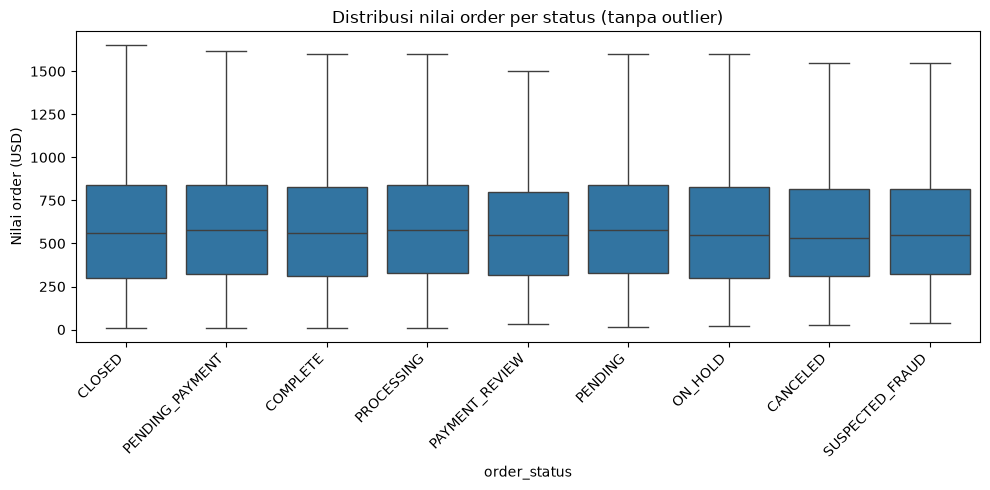

In [57]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=orders_enriched, x="order_status", y="order_revenue", showfliers=False)
plt.xticks(rotation=45, ha="right")
plt.title("Distribusi nilai order per status (tanpa outlier)")
plt.ylabel("Nilai order (USD)")
plt.tight_layout()
plt.show()

In [58]:
status_by_month = pd.crosstab(
    orders_enriched["order_month"],
    orders_enriched["order_status"],
    normalize="index",
) * 100

overall_status = orders_enriched["order_status"].value_counts(normalize=True) * 100

print("Jumlah order per bulan:")
print(orders_enriched["order_month"].value_counts().sort_index())

print("\nProporsi status per bulan (%):")
print(status_by_month.round(2))

print("\nCek: tiap baris harus berjumlah 100")
print(status_by_month.sum(axis=1).round(2))

Jumlah order per bulan:
order_month
2013-07    1533
2013-08    5680
2013-09    5841
2013-10    5335
2013-11    6381
2013-12    5892
2014-01    5908
2014-02    5635
2014-03    5778
2014-04    5657
2014-05    5467
2014-06    5308
2014-07    4468
Name: count, dtype: int64

Proporsi status per bulan (%):
order_status  CANCELED  CLOSED  COMPLETE  ON_HOLD  PAYMENT_REVIEW  PENDING  \
order_month                                                                  
2013-07           1.44   10.50     33.59     5.28            1.24    10.50   
2013-08           2.20   11.21     33.10     5.28            0.97    11.64   
2013-09           2.17   11.57     33.09     5.39            1.11    10.97   
2013-10           1.86   11.42     33.42     5.40            0.92    10.59   
2013-11           2.04   10.75     33.55     5.67            0.99    11.17   
2013-12           2.27   11.97     32.21     5.18            0.97    10.85   
2014-01           1.86   10.71     32.35     6.18            1.30    10.75

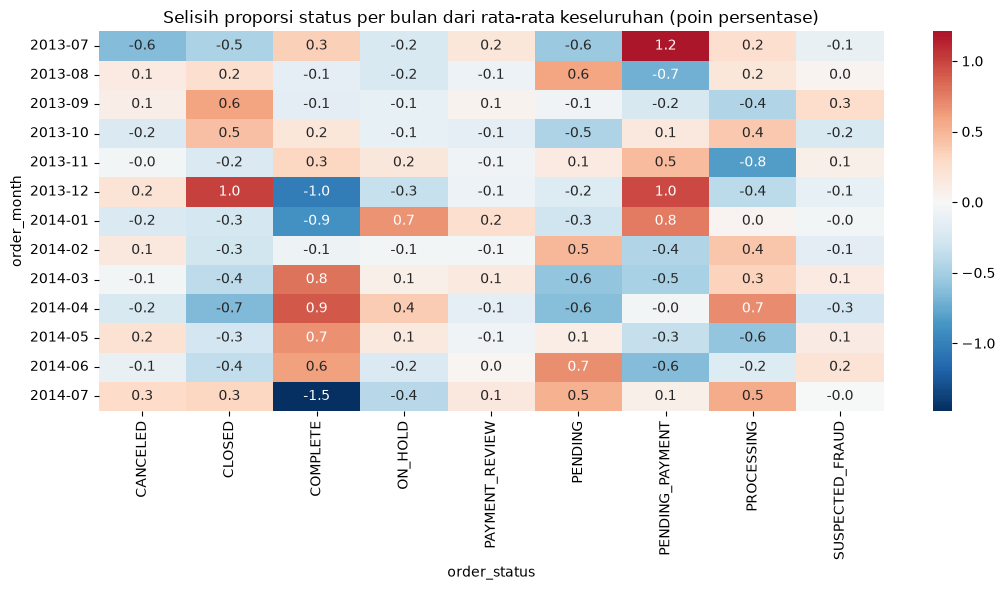

In [59]:
diff_from_overall = status_by_month - overall_status

plt.figure(figsize=(11, 6))
sns.heatmap(diff_from_overall.round(2), annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Selisih proporsi status per bulan dari rata-rata keseluruhan (poin persentase)")
plt.tight_layout()
plt.show()

In [60]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
status_by_dow = (
    pd.crosstab(orders_enriched["day_of_week"], orders_enriched["order_status"], normalize="index") * 100
).reindex(dow_order)
status_by_dow.round(2)

order_status,CANCELED,CLOSED,COMPLETE,ON_HOLD,PAYMENT_REVIEW,PENDING,PENDING_PAYMENT,PROCESSING,SUSPECTED_FRAUD
day_of_week,,,,,,,,,
Monday,2.10,10.98,33.24,5.24,0.90,11.12,22.55,11.73,2.14
Tuesday,2.31,10.92,33.68,5.60,1.08,10.70,21.37,12.21,2.13
Wednesday,2.08,11.40,33.12,5.31,0.91,10.87,22.03,12.03,2.24
Thursday,2.07,11.12,33.07,5.85,1.14,11.37,21.25,11.89,2.24
Friday,2.13,10.96,32.77,5.82,1.14,11.26,21.61,12.00,2.31
Saturday,1.83,10.59,33.92,5.81,1.06,10.89,21.66,11.88,2.35
Sunday,1.99,10.83,32.90,4.92,1.16,11.14,22.33,12.33,2.40


In [62]:
fraud_orders = orders[orders["order_status"] == "SUSPECTED_FRAUD"]
fraud_per_customer = fraud_orders.groupby("order_customer_id").size()

print("Pelanggan dengan minimal 1 order fraud :", len(fraud_per_customer))
print("Pelanggan dengan minimal 2 order fraud :", (fraud_per_customer >= 2).sum())
print(fraud_per_customer.value_counts().sort_index())

Pelanggan dengan minimal 1 order fraud : 1470
Pelanggan dengan minimal 2 order fraud : 83
1    1387
2      79
3       3
4       1
Name: count, dtype: int64


In [63]:
from scipy.stats import poisson

lam = len(fraud_orders) / customers.shape[0]    # 1558 / 12435 = 0,125
for k in [1, 2, 3]:
    expected = customers.shape[0] * (1 - poisson.cdf(k - 1, lam))
    observed = (fraud_per_customer >= k).sum()
    print(f"Minimal {k} order fraud -> perkiraan acak: {expected:.1f} | aktual: {observed}")

Minimal 1 order fraud -> perkiraan acak: 1464.3 | aktual: 1470
Minimal 2 order fraud -> perkiraan acak: 89.8 | aktual: 83
Minimal 3 order fraud -> perkiraan acak: 3.7 | aktual: 4


### Temuan H1: nilai order per status

| Status | Median | Mean | P95 | Max |
|---|---|---|---|---|
| `SUSPECTED_FRAUD` | 549,95 | 588,07 | 1.199,86 | 1.979,83 |
| `COMPLETE` | 559,94 | 594,62 | 1.199,93 | 3.449,91 |
| `CLOSED` | 559,93 | 592,93 | 1.199,90 | 2.399,96 |

- Di seluruh sembilan status, mean berkisar 582,94 sampai 607,34, median 529,97 sampai 579,95, dan p95 1.179,91 sampai 1.209,86. Tidak ada status yang menonjol.
- Median dan mean order fraud sedikit **lebih rendah** daripada order valid, dan nilai maksimumnya lebih kecil. Selisih mean sekitar 6 USD, jauh di bawah kisaran kebetulan (±10 USD untuk kelompok sebesar ini).
- **H1 tidak didukung:** order fraud tidak dapat dikenali dari nilai order saja.

### Temuan H2: proporsi status per bulan

- Jumlah order per bulan penuh berkisar 5.308 sampai 6.381. Bulan parsial: 2013-07 (1.533 order) dan 2014-07 (4.468 order).
- Proporsi status stabil. Contoh: `PENDING_PAYMENT` 21,11% sampai 23,03% (rata-rata 21,82%), `PROCESSING` 11,19% sampai 12,71%, `PENDING` 10,43% sampai 11,74%, `COMPLETE` 31,76% sampai 34,15%.
- **Tidak ada gradasi menurut umur order.** Order dari 2013-07 (sudah lebih dari setahun) masih 23,03% `PENDING_PAYMENT`, 12,26% `PROCESSING`, dan 10,50% `PENDING`, bukan mendekati nol. Bulan-bulan terbaru tidak lebih tinggi (2014-06: 21,18% dan 2014-07: 21,91% untuk `PENDING_PAYMENT`).
- Selisih terbesar dari proporsi keseluruhan sekitar 1,5 poin persentase (`COMPLETE` pada 2014-07, −1,48) dan tidak searah dari bulan ke bulan. Dengan 13 bulan × 9 status = 117 sel, beberapa selisih sebesar itu wajar terjadi kebetulan.
- **H2 tidak didukung**, baik dalam bentuk "menumpuk di bulan tertentu" maupun "belum sempat selesai".

### Temuan tambahan: pelanggan dengan order fraud

- 1.470 pelanggan (11,8% dari 12.435) punya minimal satu order fraud, 83 punya minimal dua, dan 4 punya minimal tiga (satu pelanggan sampai empat order).
- Jika 1.558 tanda fraud tersebar acak ke order (model Poisson, λ = 1.558 ÷ 12.435 ≈ 0,125), perkiraannya ±1.464 pelanggan dengan ≥1, ±90 dengan ≥2, dan ±3,7 dengan ≥3. Hasil aktual (1.470, 83, 4) sangat dekat.
- **Tidak ada bukti bahwa fraud mengelompok pada pelanggan tertentu.**

### Temuan tambahan: nilai order per status

| Kelompok | Nilai order (USD) | Porsi |
|---|---|---|
| Valid (`COMPLETE` + `CLOSED`) | 15.012.982,48 | 43,7% |
| Berjalan (`PENDING_PAYMENT`, `PROCESSING`, `PENDING`, `ON_HOLD`, `PAYMENT_REVIEW`) | 17.846.761,78 | 52,0% |
| Batal atau diduga fraud | 1.462.875,67 | 4,3% |

Total nilai order semua status: 34.322.619,93 USD. Nilai order yang masih berjalan lebih besar daripada valid revenue; nilai `PENDING_PAYMENT` saja (7.581.671,05) setara ±50% valid revenue.

### Interpretasi

Status order tampak **tidak terkait dengan nilai order, bulan, maupun pelanggan**. Karena itu tidak ada variabel di database ini yang dapat menjelaskan mengapa 56% order tidak selesai atau mengapa order ditandai fraud. Dugaan seperti "masalah di payment gateway" tidak dapat diuji dari data ini dan hanya layak ditulis sebagai hal yang perlu diperiksa di sumber data (misalnya riwayat perubahan status).

Pola seperti ini tidak lazim pada data operasional nyata: order lama biasanya sudah selesai, dan fraud biasanya terkait nilai atau pelanggan tertentu. Karena itu ada kemungkinan data ini bersifat latihan atau sintetis. Ini dugaan yang belum dikonfirmasi.

### Keterbatasan

- Data berupa satu potret tanpa riwayat perubahan status, sehingga tidak diketahui apakah order berjalan akhirnya selesai.
- Nilai order adalah nilai nominal, bukan revenue yang sudah terealisasi.
- Pengujian hanya memakai nilai order, bulan, dan pelanggan. Variabel lain (metode bayar, lokasi, perangkat) tidak tersedia.
- Orphan (11.452 order tanpa item) tidak ikut dalam perhitungan nilai order.

## Kasus 3: Distribusi Nilai Order Valid (COMPLETE dan CLOSED)

**Pertanyaan:** Seberapa bervariasi nilai order valid, dan apakah rata-rata (AOV) ±594 USD dari Query 08 mewakili order yang tipikal?

**Populasi:** 25.266 order berstatus `COMPLETE` atau `CLOSED` yang punya minimal satu item. Order valid tanpa item (5.189) tidak ikut karena tidak punya nilai.

**Metode:** statistik deskriptif dengan persentil, skewness, batas outlier metode IQR (`Q3 + 1,5 × IQR`), porsi revenue dari ±10% order terbesar, dan histogram. Hasil divalidasi dengan total revenue dan AOV dari SQL.

In [ ]:
valid_order_values = orders_enriched[
    orders_enriched["order_status"].isin(["COMPLETE", "CLOSED"])
    & orders_enriched["order_revenue"].notna()
]
rev = valid_order_values["order_revenue"]

print("Jumlah order valid yang punya item:", len(valid_order_values))      # 25266
print("Total valid revenue (USD)         :", round(rev.sum(), 2))          # 15012982.48
print("Order bernilai <= 0               :", (rev <= 0).sum())             # diharapkan 0

print("\n=== Statistik Deskriptif Valid Orders ===")
print(rev.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2))

Jumlah order valid yang punya item: 25266
Total valid revenue (USD)         : 15012982.48
Order bernilai <= 0               : 0

=== Statistik Deskriptif Valid Orders ===
count    25266.00
mean       594.20
std        344.48
min          9.99
25%        299.99
50%        559.94
75%        829.96
95%       1199.92
max       3449.91
Name: order_revenue, dtype: float64


In [ ]:
print("Mean / Median:", round(rev.mean(), 2), "/", round(rev.median(), 2))
print("Skewness     :", round(rev.skew(), 2))

q1, q3 = rev.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print("Batas outlier atas (IQR):", round(upper_fence, 2))
print("Jumlah order di atas batas:", (rev > upper_fence).sum())

p90 = rev.quantile(0.90)
print("Porsi revenue dari ~10% order terbesar:", round(rev[rev >= p90].sum() / rev.sum() * 100, 2), "%")

Mean / Median: 594.2 / 559.94
Skewness     : 0.53
Batas outlier atas (IQR): 1624.91
Jumlah order di atas batas: 58
Porsi revenue dari ~10% order terbesar: 20.97 %


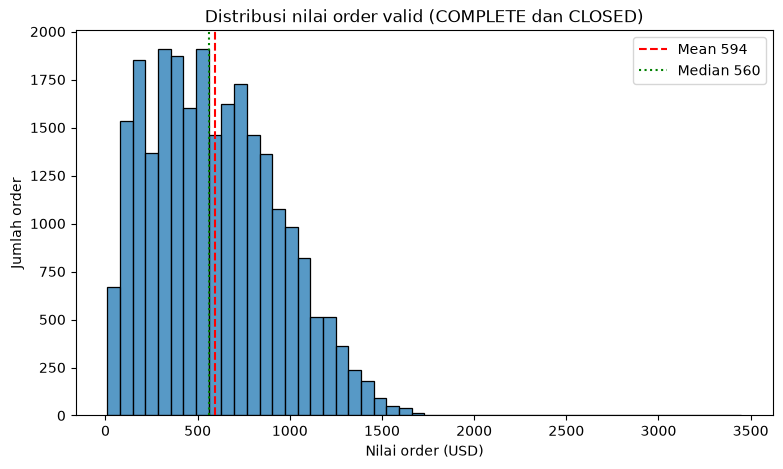

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(rev, bins=50)
plt.axvline(rev.mean(), linestyle="--", color="red", label=f"Mean {rev.mean():.0f}")
plt.axvline(rev.median(), linestyle=":", color="green", label=f"Median {rev.median():.0f}")
plt.title("Distribusi nilai order valid (COMPLETE dan CLOSED)")
plt.xlabel("Nilai order (USD)")
plt.ylabel("Jumlah order")
plt.legend()
plt.show()

In [ ]:
monthly_aov = valid_order_values.groupby("order_month")["order_revenue"].agg(
    orders="count", aov="mean"
).round(2)
monthly_aov

,orders,aov
order_month,,
2013-07,564,591.25
2013-08,2073,589.40
2013-09,2167,600.95
2013-10,1996,587.02
2013-11,2336,590.73
2013-12,2130,599.87
2014-01,2114,581.94
2014-02,2044,595.78
2014-03,2121,599.41


### Temuan

| Ukuran | Nilai (USD) |
|---|---|
| Jumlah order | 25.266 |
| Mean (AOV) | 594,20 |
| Median | 559,94 |
| Simpangan baku | 344,48 |
| Minimum | 9,99 |
| Persentil 25 | 299,99 |
| Persentil 75 | 829,96 |
| Persentil 95 | 1.199,92 |
| Maksimum | 3.449,91 |
| Skewness | 0,53 |
| Batas outlier atas (IQR) | 1.624,91 (58 order, 0,23%) |
| Porsi revenue dari ±10% order terbesar | 20,97% |

**Validasi:** total revenue 15.012.982,48 USD dan mean 594,20 sama dengan hasil SQL (Query 01 sampai 09). Tidak ada order bernilai ≤ 0.

### Interpretasi

- **Nilai order bervariasi lebar.** Separuh order di tengah (persentil 25 sampai 75) bernilai 299,99 sampai 829,96 USD. Simpangan baku 344,48 sekitar 58% dari mean.
- **AOV cukup mewakili order tipikal, tetapi sedikit lebih tinggi.** Mean 594,20 berada 34,26 USD (6,1%) di atas median 559,94, dan skewness 0,53 menunjukkan kemiringan ke kanan yang moderat. Order "di tengah" bernilai sekitar 560 USD.
- **Tidak ada ekor ekstrem.** Order terbesar (3.449,91) sekitar 5,8 kali rata-rata, hanya 58 order (0,23%) melewati batas outlier, dan 95% order bernilai ≤ 1.199,92 USD. Order di atas batas outlier tidak otomatis salah; bisa saja order besar yang sah.
- **Revenue tidak bergantung pada segelintir order besar.** Sepuluh persen order terbesar menyumbang 20,97% revenue, sekitar dua kali porsinya, jauh dari pola 80/20.
- **AOV bulanan stabil (Query 08) bukan karena semua order seragam.** Nilai tiap order sangat bervariasi, tetapi dengan ±2.000 order per bulan rata-ratanya bergerak sempit. Dengan simpangan baku 344,48, fluktuasi acak rata-rata bulanan sekitar ±15 USD, sesuai dengan kisaran AOV bulanan 581,94 sampai 603,76.

### Keterbatasan

- Populasi adalah 25.266 order valid yang punya item. Bila semua 30.455 order valid dipakai sebagai penyebut, AOV ±493 USD.
- Batas outlier IQR adalah aturan praktis, bukan hukum.
- Satuan USD adalah asumsi dari format harga; tidak ada konversi.